# ***Zee Recommender Systems***

## ***Problem Statement***

*Zee aims to improve user experience by providing personalized movie recommendations. A recommender system helps users discover movies that align with their preferences based on historical ratings and similarities among users and items.*

*In this case study, we will build different collaborative filtering based recommendation systems using:*

- *Item-Based Collaborative Filtering using Pearson Correlation*
- *Item-Based Collaborative Filtering using Cosine Similarity*
- *K-Nearest Neighbors (KNN)*
- *Matrix Factorization using Singular Value Decomposition (SVD)*


## ***Business Objective***

- *Understand user behavior and movie preferences.*
- *Build recommendation systems using collaborative filtering approaches.*
- *Evaluate Matrix Factorization models using RMSE and MAPE.*
- *Generate personalized movie recommendations to improve customer experience and engagement.*

In [1]:
# Install scikit-surprise for recommender systems
!pip install scikit-surprise

In [2]:
# Data manipulation libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Similarity Measures
from sklearn.metrics.pairwise import cosine_similarity

# KNN
from sklearn.neighbors import NearestNeighbors

# Sparse Matrix
from scipy.sparse import csr_matrix

# Matrix Factorization
from surprise import Dataset, Reader, SVD
from surprise.model_selection import train_test_split
from surprise import accuracy

# Evaluation Metrics
from sklearn.metrics import mean_absolute_percentage_error

# Display settings
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',100)

# Plot settings
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8,5)

# ***Loading the Datasets***

*The recommendation system is based on three datasets:*

1. *ratings.dat*
2. *users.dat*
3. *movies.dat*

*Since the files are separated using '::', we will use the python engine while reading the files.*

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
ratings = pd.read_csv('/content/drive/MyDrive/colab-notebooks/zee-recommendations/zee-ratings.dat',sep='::',names=['UserID','MovieID','Rating','Timestamp'],engine='python')
ratings.head()

,UserID,MovieID,Rating,Timestamp
0,UserID,MovieID,Rating,Timestamp
1,1,1193,5,978300760
2,1,661,3,978302109
3,1,914,3,978301968
4,1,3408,4,978300275


In [5]:
users = pd.read_csv('/content/drive/MyDrive/colab-notebooks/zee-recommendations/zee-users.dat',sep='::',names=['UserID','Gender','Age','Occupation','ZipCode'],engine='python')
users.head()

,UserID,Gender,Age,Occupation,ZipCode
0,UserID,Gender,Age,Occupation,Zip-code
1,1,F,1,10,48067
2,2,M,56,16,70072
3,3,M,25,15,55117
4,4,M,45,7,02460


In [6]:
movies = pd.read_csv('/content/drive/MyDrive/colab-notebooks/zee-recommendations/zee-movies.dat',sep='::',names=['MovieID','Title','Genres'],encoding='ISO-8859-1',engine='python')
movies.head()

,MovieID,Title,Genres
0,Movie ID,Title,Genres
1,1,Toy Story (1995),Animation|Children's|Comedy
2,2,Jumanji (1995),Adventure|Children's|Fantasy
3,3,Grumpier Old Men (1995),Comedy|Romance
4,4,Waiting to Exhale (1995),Comedy|Drama


# ***Understanding the Shape of Individual Datasets***

In [7]:
print("Ratings shape :", ratings.shape)
print("Users shape :", users.shape)
print("Movies shape :", movies.shape)

Ratings shape : (1000210, 4)
Users shape : (6041, 5)
Movies shape : (3884, 3)


In [8]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000210 entries, 0 to 1000209
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype 
---  ------     --------------    ----- 
 0   UserID     1000210 non-null  object
 1   MovieID    1000210 non-null  object
 2   Rating     1000210 non-null  object
 3   Timestamp  1000210 non-null  object
dtypes: object(4)
memory usage: 30.5+ MB


In [9]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6041 entries, 0 to 6040
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6041 non-null   object
 1   Gender      6041 non-null   object
 2   Age         6041 non-null   object
 3   Occupation  6041 non-null   object
 4   ZipCode     6041 non-null   object
dtypes: object(5)
memory usage: 236.1+ KB


In [10]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3884 entries, 0 to 3883
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   MovieID  3884 non-null   object
 1   Title    3884 non-null   object
 2   Genres   3884 non-null   object
dtypes: object(3)
memory usage: 91.2+ KB


## ***Observations***

- *Ratings dataset contains user ratings for movies.*
- *Users dataset contains demographic information of users.*
- *Movies dataset contains movie titles and genre information.*
- *There are no apparent datatype inconsistencies.*
- *Title and Genres are object variables whereas ratings and IDs are numerical variables.*
- *Next, we will merge all three datasets to obtain a consolidated dataframe for analysis.*

# ***Merging the Datasets***

*To perform analysis efficiently, we will merge ratings, users and movies datasets into one consolidated dataframe.*
- *Ratings and users will be merged using UserID.*
- *The resulting dataframe will then be merged with movies data using MovieID*.

In [11]:
movie_df = pd.merge(ratings, users, on='UserID')
movie_df = pd.merge(movie_df, movies, on='MovieID')
movie_df.head()

,UserID,MovieID,Rating,Timestamp,Gender,Age,Occupation,ZipCode,Title,Genres
0,1,1193,5,978300760,F,1,10,48067,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,F,1,10,48067,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,F,1,10,48067,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,F,1,10,48067,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,F,1,10,48067,"Bug's Life, A (1998)",Animation|Children's|Comedy


In [12]:
movie_df.shape

(1000209, 10)

In [13]:
movie_df.sample(5)

,UserID,MovieID,Rating,Timestamp,Gender,Age,Occupation,ZipCode,Title,Genres
651027,3927,1343,4,965710254,F,25,16,67846,Cape Fear (1991),Thriller
366276,2131,36,3,974646816,M,25,0,01701,Dead Man Walking (1995),Drama
119415,770,2718,3,979783205,M,18,4,98499,Drop Dead Gorgeous (1999),Comedy
988753,5969,1269,4,957795505,M,45,13,77706,Arsenic and Old Lace (1944),Comedy|Mystery|Thriller
1499,15,2058,3,978198516,M,25,7,22903,"Negotiator, The (1998)",Action|Thriller


In [14]:
movie_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 10 columns):
 #   Column      Non-Null Count    Dtype 
---  ------      --------------    ----- 
 0   UserID      1000209 non-null  object
 1   MovieID     1000209 non-null  object
 2   Rating      1000209 non-null  object
 3   Timestamp   1000209 non-null  object
 4   Gender      1000209 non-null  object
 5   Age         1000209 non-null  object
 6   Occupation  1000209 non-null  object
 7   ZipCode     1000209 non-null  object
 8   Title       1000209 non-null  object
 9   Genres      1000209 non-null  object
dtypes: object(10)
memory usage: 76.3+ MB


In [15]:
movie_df.describe(include='all')

,UserID,MovieID,Rating,Timestamp,Gender,Age,Occupation,ZipCode,Title,Genres
count,1000209,1000209,1000209,1000209,1000209,1000209,1000209,1000209,1000209,1000209
unique,6040,3706,5,458455,2,7,21,3439,3706,301
top,4169,2858,4,975528402,M,25,4,94110,American Beauty (1999),Comedy
freq,2314,3428,348971,30,753769,395556,131032,3802,3428,116883


In [16]:
movie_df.isnull().sum()

,0
UserID,0
MovieID,0
Rating,0
Timestamp,0
Gender,0
Age,0
Occupation,0
ZipCode,0
Title,0
Genres,0


In [17]:
movie_df.duplicated().sum()

np.int64(0)

## ***Observations***

- *After merging, the dataset contains ratings information along with user demographics and movie details.*
- *No missing values are observed in any of the columns.*
- *Duplicate records are absent.*
- *Numerical columns include UserID, MovieID, Rating, Timestamp, Age and Occupation.*
- *Title and Genres are categorical variables.*
- *Since the data quality is good, we can proceed with feature engineering.*

# ***Feature Engineering***

In [18]:
movie_df['Release_Year'] = movie_df['Title'].str.extract(r'\((\d{4})\)')

In [19]:
movie_df['Release_Year'] = movie_df['Release_Year'].astype(int)

In [20]:
movie_df[['Title','Release_Year']].head()

,Title,Release_Year
0,One Flew Over the Cuckoo's Nest (1975),1975
1,James and the Giant Peach (1996),1996
2,My Fair Lady (1964),1964
3,Erin Brockovich (2000),2000
4,"Bug's Life, A (1998)",1998


In [21]:
movie_df['Decade'] = (movie_df['Release_Year']//10)*10

In [22]:
movie_df.head()

,UserID,MovieID,Rating,Timestamp,Gender,Age,Occupation,ZipCode,Title,Genres,Release_Year,Decade
0,1,1193,5,978300760,F,1,10,48067,One Flew Over the Cuckoo's Nest (1975),Drama,1975,1970
1,1,661,3,978302109,F,1,10,48067,James and the Giant Peach (1996),Animation|Children's|Musical,1996,1990
2,1,914,3,978301968,F,1,10,48067,My Fair Lady (1964),Musical|Romance,1964,1960
3,1,3408,4,978300275,F,1,10,48067,Erin Brockovich (2000),Drama,2000,2000
4,1,2355,5,978824291,F,1,10,48067,"Bug's Life, A (1998)",Animation|Children's|Comedy,1998,1990


## ***Observations***

- *Release year has been extracted successfully from movie titles.*
- *A new variable called Decade has also been created.*
- *This feature will help us understand the distribution of movies across different decades.*
- *Feature engineering helps enrich the dataset and makes further analysis more meaningful.*

# ***Univariate Analysis***

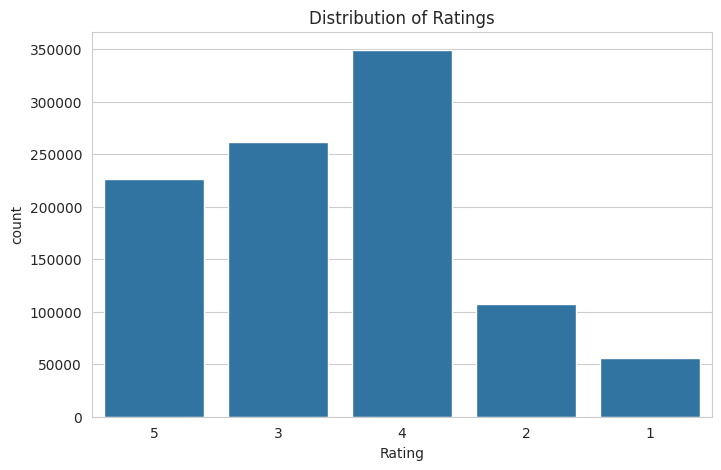

In [23]:
sns.countplot(x='Rating', data=movie_df)

plt.title('Distribution of Ratings')
plt.show()

## ***Observations***

- *Ratings are concentrated around 3, 4 and 5.*
- *Users tend to provide higher ratings more frequently.*
- *Very low ratings are relatively less common.*
- *This indicates an overall positive bias in user ratings.*

In [24]:
movie_df['Gender'].value_counts()

,count
Gender,
M,753769
F,246440


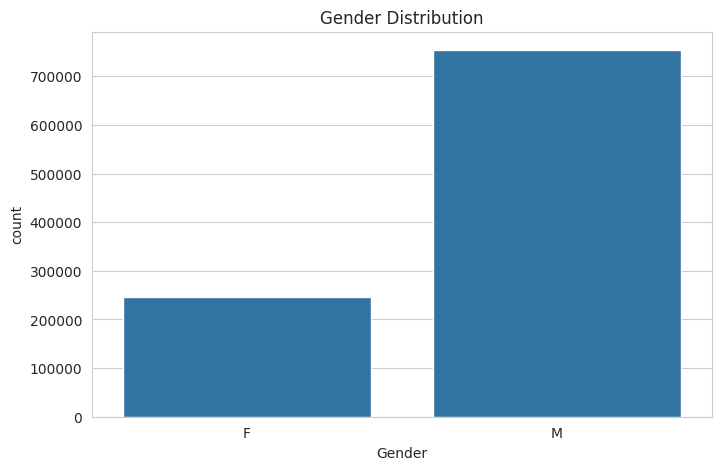

In [25]:
sns.countplot(x='Gender',data=movie_df)
plt.title("Gender Distribution")
plt.show()

## ***Observations***

- *Male users dominate the dataset.*
- *Female users represent a comparatively smaller proportion.*
- *Therefore, the statement "Most users who rated movies are male" is True.*

In [26]:
movie_df['Age'].value_counts().sort_index()

,count
Age,
1,27211
18,183536
25,395556
35,199003
45,83633
50,72490
56,38780


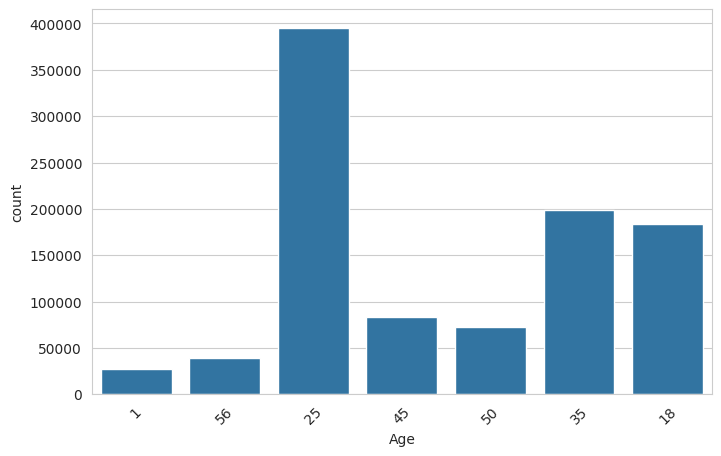

In [27]:
sns.countplot(x='Age',data=movie_df)
plt.xticks(rotation=45)
plt.show()

## ***Observations***

- *Users aged between 25 and 34 contribute the highest number of ratings.*
- *Young adults form the major customer segment in this dataset.*
- *Understanding age distribution helps in personalization and targeted recommendations.*

# ***Occupation Analysis***

In [28]:
movie_df['Occupation'].value_counts().sort_values(ascending=False).head(10)

,count
Occupation,
4,131032
0,130499
7,105425
1,85351
17,72816
20,60397
12,57214
2,50068
14,49109


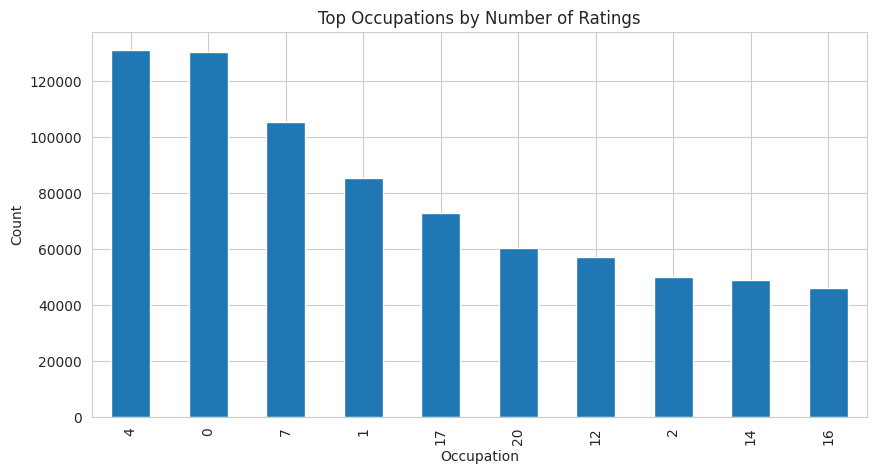

In [29]:
plt.figure(figsize=(10,5))
movie_df['Occupation'].value_counts().head(10).plot(kind='bar')
plt.title('Top Occupations by Number of Ratings')
plt.ylabel('Count')
plt.show()

## ***Observations***

- *Few occupation groups contribute a major proportion of ratings.*
- *Occupation can influence movie preferences.*
- *Profession-based recommendations may improve personalization.*

# ***Release Year Analysis***

In [30]:
movie_df['Release_Year'].describe()

,Release_Year
count,1.000209e+06
mean,1.986698e+03
std,1.434933e+01
min,1.919000e+03
25%,1.982000e+03
50%,1.992000e+03
75%,1.997000e+03
max,2.000000e+03


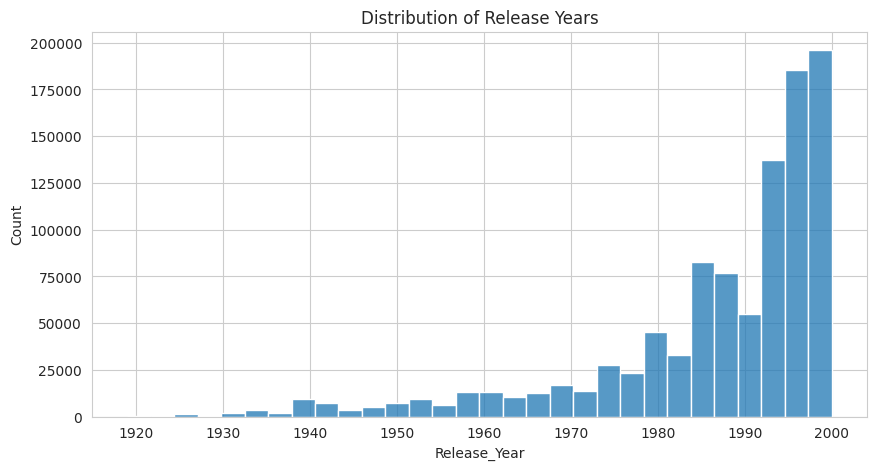

In [31]:
plt.figure(figsize=(10,5))
sns.histplot(movie_df['Release_Year'], bins=30)
plt.title('Distribution of Release Years')
plt.show()

## ***Observations***

- *Majority of movies belong to the late twentieth century.*
- *Movie production increased significantly during the 1990s.*
- *There are relatively fewer movies from earlier decades.*

In [32]:
movie_df['Decade'].value_counts().sort_index()

,count
Decade,
1910,45
1920,1696
1930,12729
1940,21501
1950,35232
1960,48555
1970,82552
1980,224056
1990,532843


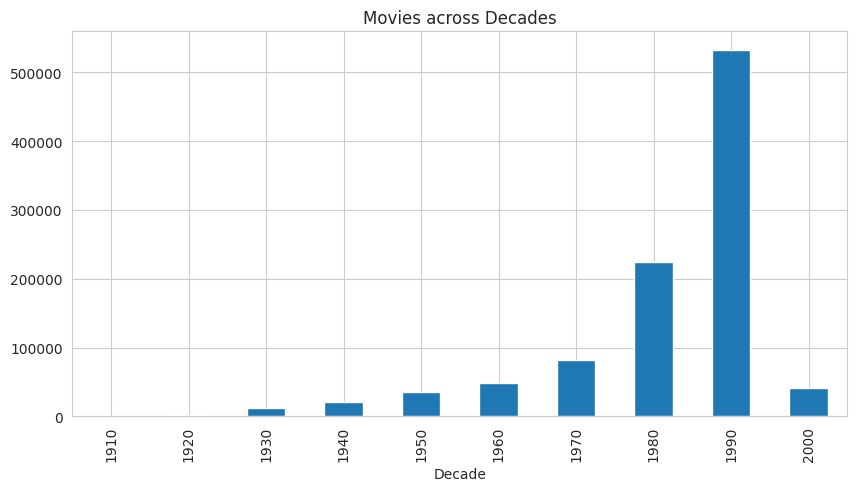

In [33]:
plt.figure(figsize=(10,5))
movie_df['Decade'].value_counts().sort_index().plot(kind='bar')
plt.title('Movies across Decades')
plt.show()

## ***Observations***

- *The 1990s contain the highest number of movies.*
- *Hence, most movies present in the dataset were released during the 1990s.*

# ***Average Ratings and Number of Ratings***

In [34]:
movie_df['Rating'] = pd.to_numeric(movie_df['Rating'], errors='coerce')
movie_df.dropna(subset=['Rating'], inplace=True)
movie_rating = movie_df.groupby('Title')['Rating'].agg(['mean','count'])
movie_rating.head()

,mean,count
Title,,
"$1,000,000 Duck (1971)",3.027027,37
'Night Mother (1986),3.371429,70
'Til There Was You (1997),2.692308,52
"'burbs, The (1989)",2.910891,303
...And Justice for All (1979),3.713568,199


In [35]:
movie_rating.columns = ['Average_Rating','Number_of_Ratings']
movie_rating.head()

,Average_Rating,Number_of_Ratings
Title,,
"$1,000,000 Duck (1971)",3.027027,37
'Night Mother (1986),3.371429,70
'Til There Was You (1997),2.692308,52
"'burbs, The (1989)",2.910891,303
...And Justice for All (1979),3.713568,199


In [36]:
movie_rating.describe()

,Average_Rating,Number_of_Ratings
count,3706.000000,3706.000000
mean,3.238892,269.889099
std,0.672925,384.047838
min,1.000000,1.000000
25%,2.822705,33.000000
50%,3.331546,123.500000
75%,3.740741,350.000000
max,5.000000,3428.000000


In [37]:
movie_rating.sort_values('Number_of_Ratings',ascending=False).head(10)

,Average_Rating,Number_of_Ratings
Title,,
American Beauty (1999),4.317386,3428
Star Wars: Episode IV - A New Hope (1977),4.453694,2991
Star Wars: Episode V - The Empire Strikes Back (1980),4.292977,2990
Star Wars: Episode VI - Return of the Jedi (1983),4.022893,2883
Jurassic Park (1993),3.763847,2672
Saving Private Ryan (1998),4.337354,2653
Terminator 2: Judgment Day (1991),4.058513,2649
"Matrix, The (1999)",4.315830,2590
Back to the Future (1985),3.990321,2583


## ***Observations***

- *Some movies receive a very high number of ratings.*
- *Popular movies tend to have more stable average ratings.*
- *Movies with very few ratings may not provide reliable recommendations.*

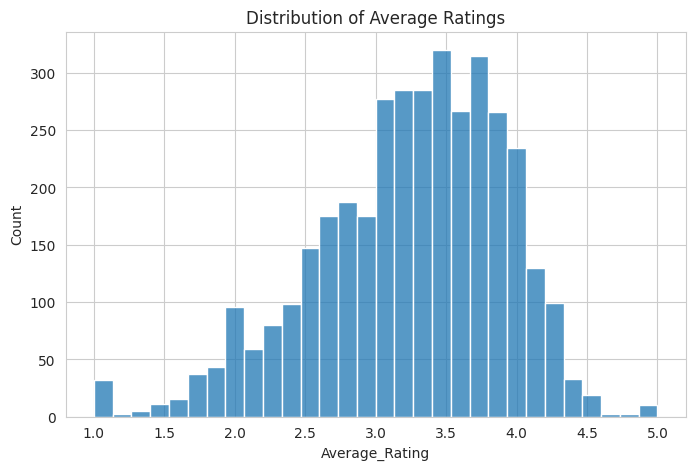

In [38]:
plt.figure(figsize=(8,5))
sns.histplot(movie_rating['Average_Rating'], bins=30)
plt.title('Distribution of Average Ratings')
plt.show()

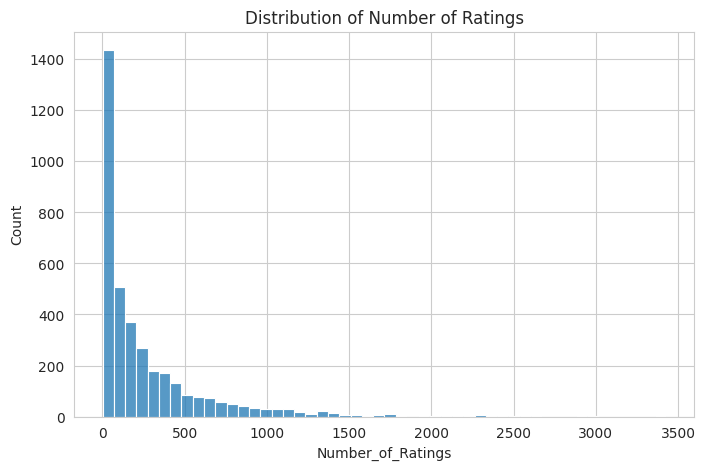

In [39]:
plt.figure(figsize=(8,5))
sns.histplot(movie_rating['Number_of_Ratings'], bins=50)
plt.title('Distribution of Number of Ratings')
plt.show()

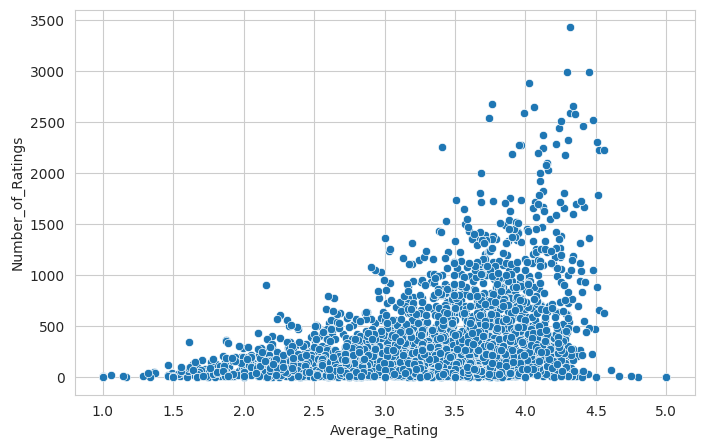

In [40]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=movie_rating,x='Average_Rating',y='Number_of_Ratings')
plt.show()

## ***Observations***

- *Most movies have relatively few ratings.*
- *Popular movies tend to cluster towards higher number of ratings.*
- *Highly rated movies with sufficient ratings are ideal candidates for recommendation systems.*

In [41]:
movie_rating.sort_values('Number_of_Ratings',ascending=False).head(1)

,Average_Rating,Number_of_Ratings
Title,,
American Beauty (1999),4.317386,3428


# ***Questionnaire Answer***

***The movie with the maximum number of ratings can be obtained from the above output.***

# ***Creating User-Item Matrix***

*For collaborative filtering, we transform the dataset into a pivot table where:*

- *Rows represent Users.*
- *Columns represent Movies.*
- *Values represent Ratings.*

In [42]:
movie_pivot = movie_df.pivot_table(index='UserID',columns='Title',values='Rating')
movie_pivot.head()

Title   $1,000,000 Duck (1971)  'Night Mother (1986)  \
UserID                                                 
1                          NaN                   NaN   
10                         NaN                   NaN   
100                        NaN                   NaN   
1000                       NaN                   NaN   
1001                       NaN                   NaN   

Title   'Til There Was You (1997)  'burbs, The (1989)  \
UserID                                                  
1                             NaN                 NaN   
10                            NaN                 4.0   
100                           NaN                 NaN   
1000                          NaN                 NaN   
1001                          NaN                 NaN   

Title   ...And Justice for All (1979)  1-900 (1994)  \
UserID                                                
1                                 NaN           NaN   
10                                NaN           NaN   
100                               NaN           NaN   
1000                              NaN           NaN   
1001                              NaN           NaN   

Title   10 Things I Hate About You (1999)  101 Dalmatians (1961)  \
UserID                                                             
1                                     NaN                    NaN   
10                                    NaN                    NaN   
100                                   NaN                    NaN   
1000                                  NaN                    4.0   
1001                                  NaN                    NaN   

Title   101 Dalmatians (1996)  12 Angry Men (1957)  13th Warrior, The (1999)  \
UserID                                                                         
1                         NaN                  NaN                       NaN   
10                        NaN                  3.0                       4.0   
100                       NaN                  NaN                       NaN   
1000                      NaN                  NaN                       NaN   
1001                      3.0                  NaN                       NaN   

Title   187 (1997)  2 Days in the Valley (1996)  20 Dates (1998)  \
UserID                                                             
1              NaN                          NaN              NaN   
10             NaN                          NaN              NaN   
100            NaN                          NaN              NaN   
1000           NaN                          NaN              NaN   
1001           NaN                          NaN              NaN   

Title   20,000 Leagues Under the Sea (1954)  200 Cigarettes (1999)  \
UserID                                                               
1                                       NaN                    NaN   
10                                      4.0                    NaN   
100                                     NaN                    NaN   
1000                                    NaN                    NaN   
1001                                    NaN                    1.0   

Title   2001: A Space Odyssey (1968)  2010 (1984)  \
UserID                                              
1                                NaN          NaN   
10                               3.0          NaN   
100                              4.0          NaN   
1000                             NaN          NaN   
1001                             NaN          NaN   

Title   24 7: Twenty Four Seven (1997)  24-hour Woman (1998)  28 Days (2000)  \
UserID                                                                         
1                                  NaN                   NaN             NaN   
10                                 NaN                   NaN             NaN   
100                                NaN                   NaN             NaN   
1000                               NaN     

In [43]:
movie_pivot.shape

(6040, 3706)

In [44]:
movie_pivot.isnull().sum().head()

,0
Title,
"$1,000,000 Duck (1971)",6003
'Night Mother (1986),5970
'Til There Was You (1997),5988
"'burbs, The (1989)",5737
...And Justice for All (1979),5841


In [45]:
movie_pivot.fillna(0,inplace=True)
movie_pivot.head()

Title   $1,000,000 Duck (1971)  'Night Mother (1986)  \
UserID                                                 
1                          0.0                   0.0   
10                         0.0                   0.0   
100                        0.0                   0.0   
1000                       0.0                   0.0   
1001                       0.0                   0.0   

Title   'Til There Was You (1997)  'burbs, The (1989)  \
UserID                                                  
1                             0.0                 0.0   
10                            0.0                 4.0   
100                           0.0                 0.0   
1000                          0.0                 0.0   
1001                          0.0                 0.0   

Title   ...And Justice for All (1979)  1-900 (1994)  \
UserID                                                
1                                 0.0           0.0   
10                                0.0           0.0   
100                               0.0           0.0   
1000                              0.0           0.0   
1001                              0.0           0.0   

Title   10 Things I Hate About You (1999)  101 Dalmatians (1961)  \
UserID                                                             
1                                     0.0                    0.0   
10                                    0.0                    0.0   
100                                   0.0                    0.0   
1000                                  0.0                    4.0   
1001                                  0.0                    0.0   

Title   101 Dalmatians (1996)  12 Angry Men (1957)  13th Warrior, The (1999)  \
UserID                                                                         
1                         0.0                  0.0                       0.0   
10                        0.0                  3.0                       4.0   
100                       0.0                  0.0                       0.0   
1000                      0.0                  0.0                       0.0   
1001                      3.0                  0.0                       0.0   

Title   187 (1997)  2 Days in the Valley (1996)  20 Dates (1998)  \
UserID                                                             
1              0.0                          0.0              0.0   
10             0.0                          0.0              0.0   
100            0.0                          0.0              0.0   
1000           0.0                          0.0              0.0   
1001           0.0                          0.0              0.0   

Title   20,000 Leagues Under the Sea (1954)  200 Cigarettes (1999)  \
UserID                                                               
1                                       0.0                    0.0   
10                                      4.0                    0.0   
100                                     0.0                    0.0   
1000                                    0.0                    0.0   
1001                                    0.0                    1.0   

Title   2001: A Space Odyssey (1968)  2010 (1984)  \
UserID                                              
1                                0.0          0.0   
10                               3.0          0.0   
100                              4.0          0.0   
1000                             0.0          0.0   
1001                             0.0          0.0   

Title   24 7: Twenty Four Seven (1997)  24-hour Woman (1998)  28 Days (2000)  \
UserID                                                                         
1                                  0.0                   0.0             0.0   
10                                 0.0                   0.0             0.0   
100                                0.0                   0.0             0.0   
1000                               0.0     

## ***Observations***

- *Missing ratings are represented as zeros.*
- *The matrix is sparse because every user has rated only a small subset of movies.*
- *This pivot table forms the basis of collaborative filtering techniques.*

# ***Item-Based Collaborative Filtering using Pearson Correlation***

*Item-based collaborative filtering recommends movies that are similar to a given movie based on users' rating patterns.*

*Pearson Correlation is used to measure the linear relationship between two movies.*

In [46]:
corr_matrix = movie_pivot.corr(method='pearson')
corr_matrix.head()

Title                          $1,000,000 Duck (1971)  'Night Mother (1986)  \
Title                                                                         
$1,000,000 Duck (1971)                       1.000000              0.065338   
'Night Mother (1986)                         0.065338              1.000000   
'Til There Was You (1997)                    0.030805              0.107374   
'burbs, The (1989)                           0.065478              0.096778   
...And Justice for All (1979)                0.048708              0.144480   

Title                          'Til There Was You (1997)  'burbs, The (1989)  \
Title                                                                          
$1,000,000 Duck (1971)                          0.030805            0.065478   
'Night Mother (1986)                            0.107374            0.096778   
'Til There Was You (1997)                       1.000000            0.082706   
'burbs, The (1989)                              0.082706            1.000000   
...And Justice for All (1979)                   0.051965            0.110790   

Title                          ...And Justice for All (1979)  1-900 (1994)  \
Title                                                                        
$1,000,000 Duck (1971)                              0.048708     -0.001319   
'Night Mother (1986)                                0.144480     -0.001834   
'Til There Was You (1997)                           0.051965      0.079011   
'burbs, The (1989)                                  0.110790     -0.003821   
...And Justice for All (1979)                       1.000000     -0.003203   

Title                          10 Things I Hate About You (1999)  \
Title                                                              
$1,000,000 Duck (1971)                                  0.036612   
'Night Mother (1986)                                    0.046122   
'Til There Was You (1997)                               0.105672   
'burbs, The (1989)                                      0.133881   
...And Justice for All (1979)                           0.018614   

Title                          101 Dalmatians (1961)  101 Dalmatians (1996)  \
Title                                                                         
$1,000,000 Duck (1971)                      0.176528               0.159973   
'Night Mother (1986)                        0.123378               0.074706   
'Til There Was You (1997)                   0.091422               0.108952   
'burbs, The (1989)                          0.198168               0.134041   
...And Justice for All (1979)               0.151020               0.078917   

Title                          12 Angry Men (1957)  13th Warrior, The (1999)  \
Title                                                                          
$1,000,000 Duck (1971)                    0.075665                  0.036112   
'Night Mother (1986)                      0.083988                  0.013045   
'Til There Was You (1997)                 0.054821                  0.040220   
'burbs, The (1989)                        0.113112                  0.139186   
...And Justice for All (1979)             0.160556                  0.068781   

Title                          187 (1997)  2 Days in the Valley (1996)  \
Title                                                                    
$1,000,000 Duck (1971)           0.021743                     0.005995   
'Night Mother (1986)             0.051613                     0.089638   
'Til There Was You (1997)        0.012265                     0.050856   
'burbs, The (1989)               0.086871                     0.146527   
...And Justice for All (1979)    0.100455                     0.164416   

Title                          20 Dates (1998)  \
Title                                            
$1,000,000 Duck (1971)                0.006623   
'Night Mother (1986)                  0.024013   
'Til There Was You (1997)  

In [47]:
corr_matrix.shape

(3706, 3706)

## ***Observations***

- *Pearson Correlation ranges from -1 to +1.*
- *Values close to +1 indicate strong positive similarity.*
- *Values close to -1 indicate strong negative similarity.*
- *Movies with higher correlation tend to receive similar ratings from users.*

In [48]:
movie_name = 'Liar Liar (1997)'
similar_movies = corr_matrix[movie_name].sort_values(ascending=False)
similar_movies.head(10)

,Liar Liar (1997)
Title,
Liar Liar (1997),1.000000
Mrs. Doubtfire (1993),0.499927
Dumb & Dumber (1994),0.459601
Ace Ventura: Pet Detective (1994),0.458654
Home Alone (1990),0.455967
"Wedding Singer, The (1998)",0.429222
Wayne's World (1992),0.424552
"Cable Guy, The (1996)",0.420942
Tommy Boy (1995),0.413143


In [49]:
top_3_similar = similar_movies.iloc[1:4]
top_3_similar

,Liar Liar (1997)
Title,
Mrs. Doubtfire (1993),0.499927
Dumb & Dumber (1994),0.459601
Ace Ventura: Pet Detective (1994),0.458654


# ***Questionnaire Answer***

***The top 3 movies similar to 'Liar Liar (1997)' can be obtained from the above output.***

In [50]:
def recommend_movies_pearson(movie_name, n=5):
    similar_movies = corr_matrix[movie_name].sort_values(ascending=False)
    return similar_movies.iloc[1:n+1]

In [51]:
recommend_movies_pearson('Liar Liar (1997)')

,Liar Liar (1997)
Title,
Mrs. Doubtfire (1993),0.499927
Dumb & Dumber (1994),0.459601
Ace Ventura: Pet Detective (1994),0.458654
Home Alone (1990),0.455967
"Wedding Singer, The (1998)",0.429222


# ***Cosine Similarity***

*Cosine similarity measures the angle between vectors and lies between 0 and 1.*

*Values closer to 1 indicate stronger similarity.*

In [52]:
item_similarity = cosine_similarity(movie_pivot.T)

In [53]:
item_similarity.shape

(3706, 3706)

In [54]:
item_similarity_df = pd.DataFrame(item_similarity,index=movie_pivot.columns,columns=movie_pivot.columns)
item_similarity_df.head()

Title                          $1,000,000 Duck (1971)  'Night Mother (1986)  \
Title                                                                         
$1,000,000 Duck (1971)                       1.000000              0.072357   
'Night Mother (1986)                         0.072357              1.000000   
'Til There Was You (1997)                    0.037011              0.115290   
'burbs, The (1989)                           0.079291              0.115545   
...And Justice for All (1979)                0.060838              0.159526   

Title                          'Til There Was You (1997)  'burbs, The (1989)  \
Title                                                                          
$1,000,000 Duck (1971)                          0.037011            0.079291   
'Night Mother (1986)                            0.115290            0.115545   
'Til There Was You (1997)                       1.000000            0.098756   
'burbs, The (1989)                              0.098756            1.000000   
...And Justice for All (1979)                   0.066301            0.143620   

Title                          ...And Justice for All (1979)  1-900 (1994)  \
Title                                                                        
$1,000,000 Duck (1971)                              0.060838       0.00000   
'Night Mother (1986)                                0.159526       0.00000   
'Til There Was You (1997)                           0.066301       0.08025   
'burbs, The (1989)                                  0.143620       0.00000   
...And Justice for All (1979)                       1.000000       0.00000   

Title                          10 Things I Hate About You (1999)  \
Title                                                              
$1,000,000 Duck (1971)                                  0.058619   
'Night Mother (1986)                                    0.076798   
'Til There Was You (1997)                               0.127895   
'burbs, The (1989)                                      0.192191   
...And Justice for All (1979)                           0.075093   

Title                          101 Dalmatians (1961)  101 Dalmatians (1996)  \
Title                                                                         
$1,000,000 Duck (1971)                      0.189965               0.172254   
'Night Mother (1986)                        0.147437               0.095922   
'Til There Was You (1997)                   0.112654               0.125670   
'burbs, The (1989)                          0.246927               0.175885   
...And Justice for All (1979)               0.194154               0.116379   

Title                          12 Angry Men (1957)  13th Warrior, The (1999)  \
Title                                                                          
$1,000,000 Duck (1971)                    0.094785                  0.058418   
'Night Mother (1986)                      0.111413                  0.046135   
'Til There Was You (1997)                 0.079115                  0.066598   
'burbs, The (1989)                        0.170719                  0.197808   
...And Justice for All (1979)             0.205486                  0.122431   

Title                          187 (1997)  2 Days in the Valley (1996)  \
Title                                                                    
$1,000,000 Duck (1971)           0.028171                     0.021295   
'Night Mother (1986)             0.060254                     0.108613   
'Til There Was You (1997)        0.019914                     0.067742   
'burbs, The (1989)               0.103273                     0.183970   
...And Justice for All (1979)    0.114231                     0.195255   

Title                          20 Dates (1998)  \
Title                                            
$1,000,000 Duck (1971)                0.016918   
'Night Mother (1986)                  0.038041   
'Til There Was You (1997)  

In [55]:
item_similarity_df.iloc[:5,:5]

Title,"$1,000,000 Duck (1971)",'Night Mother (1986),'Til There Was You (1997),"'burbs, The (1989)",...And Justice for All (1979)
Title,,,,,
"$1,000,000 Duck (1971)",1.000000,0.072357,0.037011,0.079291,0.060838
'Night Mother (1986),0.072357,1.000000,0.115290,0.115545,0.159526
'Til There Was You (1997),0.037011,0.115290,1.000000,0.098756,0.066301
"'burbs, The (1989)",0.079291,0.115545,0.098756,1.000000,0.143620
...And Justice for All (1979),0.060838,0.159526,0.066301,0.143620,1.000000


## ***Observations***

- *Diagonal elements are equal to 1 since every movie is perfectly similar to itself.*
- *Similarity values closer to 1 indicate stronger resemblance.*
- *Item-item similarity matrix forms the basis of recommendation systems.*

In [56]:
user_similarity = cosine_similarity(movie_pivot)

In [57]:
user_similarity.shape

(6040, 6040)

In [58]:
user_similarity_df = pd.DataFrame(user_similarity,index=movie_pivot.index,columns=movie_pivot.index)
user_similarity_df.head()

UserID         1        10       100      1000      1001      1002      1003  \
UserID                                                                         
1       1.000000  0.255288  0.123967  0.207800  0.139061  0.110320  0.121384   
10      0.255288  1.000000  0.258047  0.278753  0.154858  0.112222  0.141111   
100     0.123967  0.258047  1.000000  0.297539  0.075597  0.110450  0.358686   
1000    0.207800  0.278753  0.297539  1.000000  0.094710  0.047677  0.201722   
1001    0.139061  0.154858  0.075597  0.094710  1.000000  0.164551  0.053788   

UserID      1004      1005      1006      1007      1008      1009       101  \
UserID                                                                         
1       0.179143  0.103137  0.052816  0.060032  0.102675  0.049839  0.029990   
10      0.428224  0.188569  0.101856  0.160734  0.219440  0.115671  0.204174   
100     0.236065  0.171609  0.099147  0.060103  0.043367  0.061238  0.347549   
1000    0.353782  0.323584  0.130702  0.042828  0.077724  0.123638  0.282423   
1001    0.149019  0.137336  0.134462  0.019540  0.083497  0.200043  0.067775   

UserID      1010      1011      1012      1013      1014      1015      1016  \
UserID                                                                         
1       0.158998  0.078094  0.080898  0.047769  0.195850  0.175148  0.132802   
10      0.348802  0.198759  0.152132  0.156608  0.157343  0.390245  0.200637   
100     0.262156  0.139793  0.085678  0.024211  0.292006  0.194110  0.171057   
1000    0.248381  0.124237  0.117258  0.050799  0.179805  0.217813  0.090189   
1001    0.251583  0.072368  0.037393  0.073467  0.059556  0.298098  0.293565   

UserID      1017      1018      1019       102      1020      1021      1022  \
UserID                                                                         
1       0.142788  0.178819  0.112310  0.119980  0.034848  0.090209  0.111133   
10      0.283837  0.239921  0.331964  0.162295  0.107090  0.189606  0.108169   
100     0.141068  0.337496  0.192321  0.009131  0.176147  0.195809  0.070161   
1000    0.196132  0.364062  0.200980  0.102801  0.141890  0.170695  0.056812   
1001    0.100733  0.065301  0.165053  0.174044  0.154019  0.094506  0.266318   

UserID      1023      1024      1025      1026      1027      1028      1029  \
UserID                                                                         
1       0.099425  0.022982  0.028506  0.004729  0.143985  0.045708  0.187819   
10      0.126938  0.136483  0.075916  0.037347  0.146672  0.083205  0.291860   
100     0.087403  0.066152  0.070635  0.031957  0.211235  0.098388  0.149484   
1000    0.039899  0.018445  0.115536  0.029414  0.152463  0.069294  0.220646   
1001    0.048713  0.066258  0.119893  0.126163  0.076968  0.045484  0.153981   

UserID       103      1030      1031      1032      1033      1034      1035  \
UserID                                                                         
1       0.032611  0.045869  0.057829  0.181461  0.031882  0.189666  0.136573   
10      0.152799  0.235402  0.271768  0.226634  0.201777  0.329064  0.124660   
100     0.223646  0.400578  0.387974  0.092417  0.141394  0.160494  0.222814   
1000    0.167508  0.341998  0.322370  0.143107  0.128474  0.231461  0.130871   
1001    0.098262  0.088469  0.081548  0.226173  0.102571  0.144300  0.100802   

UserID      1036      1037      1038      1039       104      1040      1041  \
UserID                                                                         
1       0.136320  0.022805  0.178207  0.030367  0.047547  0.174008  0.044921   
10      0.167810  0.048167  0.177751  0.048105  0.078346  0.333208  0.075434   
100     0.189875  0.046555  0.128930  0.000000  0.030602  0.226101  0.080412   
1000    0.131125  0.059484  0.089262  0.000000  0.067599  0.229626  0.040560   
1001    0.076212  0.201611  0.158414  0.080222  0.130191  0.126016  0.081913   

UserID      1042      1043      1044      1045      1046      1047      1

## ***Observations***

- *User-user similarity matrix captures how similar users are based on their rating behavior.*
- *Users having similar preferences tend to receive similar recommendations.*

# ***Questionnaire Answer***

***Based on approach, collaborative filtering methods are classified into:***

- ***User-Based***
- ***Item-Based***

# ***Questionnaire Answer***

***Pearson Correlation ranges from -1 to +1.***

***Cosine Similarity ranges from 0 to 1.***

# ***Sparse Matrix Representation***

*Since the user-item matrix contains many zeros, it is converted into a sparse matrix for efficient storage and computation.*

In [59]:
csr_data = csr_matrix(movie_pivot.values)
csr_data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1000209 stored elements and shape (6040, 3706)>

# ***Questionnaire Answer***

***For the dense matrix***

**[[1 0]
 [3 7]]**

***Sparse row representation is:***

***Row 0 → (0,1)***

***Row 1 → (0,3), (1,7)***

# ***K-Nearest Neighbors using Cosine Similarity***

In [60]:
knn_model = NearestNeighbors(metric='cosine',algorithm='brute')
knn_model.fit(csr_data)

NearestNeighbors(algorithm='brute', metric='cosine')

In [61]:
movie_list = list(movie_pivot.columns)

In [62]:
movie_index = movie_list.index('Liar Liar (1997)')
movie_index

1919

In [64]:
item_csr_data = csr_matrix(movie_pivot.T.values)

# Create and fit a new KNN model for item-based similarity
knn_model_item_based = NearestNeighbors(metric='cosine', algorithm='brute')
knn_model_item_based.fit(item_csr_data)

# Now use this new model to find neighbors for the selected movie
distances, indices = knn_model_item_based.kneighbors(movie_pivot.T.iloc[movie_index,:].values.reshape(1,-1), n_neighbors=6)

In [65]:
for i in range(1,len(distances.flatten())):
    print(movie_pivot.columns[indices.flatten()[i]])


Mrs. Doubtfire (1993)
Ace Ventura: Pet Detective (1994)
Dumb & Dumber (1994)
Home Alone (1990)
Wayne's World (1992)


## ***Observations***

- *KNN recommends movies based on nearest neighbors.*
- *Movies having similar rating patterns are grouped together.*
- *Cosine distance helps identify similar movies even in sparse datasets.*

# ***Matrix Factorization using Singular Value Decomposition (SVD)***

*Matrix Factorization decomposes the user-item matrix into latent factors that capture hidden relationships between users and movies.*

*In this analysis, we use SVD with latent dimension (d = 4).*

In [66]:
reader = Reader(rating_scale=(1,5))
data = Dataset.load_from_df(movie_df[['UserID','MovieID','Rating']],reader)

In [67]:
trainset, testset = train_test_split(data,test_size=0.2,random_state=42)

In [68]:
svd_model = SVD(n_factors=4,random_state=42)

In [69]:
svd_model.fit(trainset)

In [70]:
predictions = svd_model.test(testset)

In [71]:
rmse = accuracy.rmse(predictions)

RMSE: 0.8830


In [72]:
actual = []
predicted = []

for pred in predictions:
    actual.append(pred.r_ui)
    predicted.append(pred.est)

In [73]:
mape = mean_absolute_percentage_error(actual,predicted)
print("MAPE :",mape)

MAPE : 0.2695129372787126


## ***Observations***

- *SVD captures latent relationships between users and movies.*
- *Matrix Factorization reduces dimensionality and improves recommendations.*
- *Lower RMSE indicates better prediction accuracy.*
- *MAPE measures percentage error between actual and predicted ratings.*

# ***Questionnaire Answer***

*The RMSE and MAPE obtained can be reported from the above outputs.*

# ***Movie Embeddings***

*SVD learns latent embeddings for movies.*

*These embeddings can be used for similarity-based recommendations.*

In [74]:
movie_embeddings = svd_model.qi
movie_embeddings.shape

(3675, 4)

In [75]:
movie_embeddings[:5]

array([[-0.35171344, -0.56880433, -0.04959003,  0.06761054],
       [-0.40644456,  0.33418722,  0.14369058,  0.09612914],
       [ 0.6529544 , -0.78429462, -0.18575613,  0.10038926],
       [-0.2758218 , -0.82445732,  1.23624921, -0.18871644],
       [ 0.47574572, -0.37559472, -0.04741572,  0.16923175]])

In [76]:
user_embeddings = svd_model.pu
user_embeddings.shape

(6040, 4)

## ***Observations***

- *User embeddings represent latent preferences of users.*
- *Movie embeddings represent latent characteristics of movies.*
- *Similar embeddings correspond to similar movies and users.*

# Visualizing Embeddings in Two Dimensions

In [77]:
from sklearn.decomposition import PCA

In [78]:
pca = PCA(n_components=2)
movie_embedding_2d = pca.fit_transform(movie_embeddings)

In [79]:
movie_embedding_2d.shape

(3675, 2)

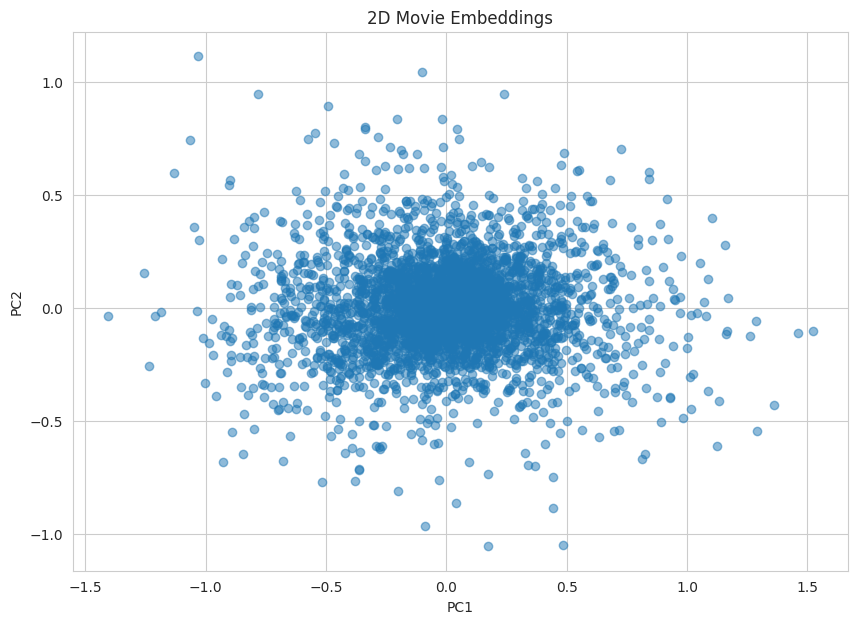

In [80]:
plt.figure(figsize=(10,7))
plt.scatter(movie_embedding_2d[:,0],movie_embedding_2d[:,1],alpha=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('2D Movie Embeddings')
plt.show()

## ***Observations***

- *Movies having similar latent features tend to cluster together.*
- *Matrix Factorization provides meaningful representations of movies.*
- *Visualization helps understand hidden structures in the data.*

# ***Insights and Recommendations***

## ***Insights***

- *Male users dominate the dataset.*
- *Users aged 25-34 contribute the maximum ratings.*
- *Most movies belong to the 1990s.*
- *The user-item matrix is highly sparse.*
- *Collaborative filtering effectively captures similarities among movies.*
- *Pearson correlation and cosine similarity provide item-based recommendations.*
- *Matrix Factorization captures latent interactions and improves prediction accuracy.*

## ***Recommendations***

1. *Personalized recommendations should be implemented using Matrix Factorization due to its ability to capture hidden relationships.*
2. *Popular movies with high average ratings can be promoted to new users.*
3. *Hybrid recommendation systems combining collaborative filtering and content-based filtering may further improve performance.*
4. *Movie embeddings can be leveraged to build advanced recommendation engines.*
5. *User demographics such as age and occupation can be incorporated to enhance personalization.*

# ***Extra Section : User-Based Collaborative Filtering***

*In User-Based Collaborative Filtering, users with similar preferences are identified and recommendations are generated based on ratings provided by similar users*.

*The similarity between users is calculated using Pearson Correlation.*

In [81]:
new_user = {'Toy Story (1995)':5,'Jumanji (1995)':4,'Heat (1995)':5,'GoldenEye (1995)':3,'Liar Liar (1997)':5}

In [82]:
new_user_df = pd.DataFrame(new_user.items(),columns=['Title','Rating'])
new_user_df

,Title,Rating
0,Toy Story (1995),5
1,Jumanji (1995),4
2,Heat (1995),5
3,GoldenEye (1995),3
4,Liar Liar (1997),5


# ***Finding Users who have Rated the Same Movies***

In [83]:
common_users = movie_df[movie_df['Title'].isin(new_user_df['Title'])]
common_users.head()

,UserID,MovieID,Rating,Timestamp,Gender,Age,Occupation,ZipCode,Title,Genres,Release_Year,Decade
40,1,1,5,978824268,F,1,10,48067,Toy Story (1995),Animation|Children's|Comedy,1995,1990
297,5,6,2,978245916,M,25,20,55455,Heat (1995),Action|Crime|Thriller,1995,1990
324,5,1485,3,978246576,M,25,20,55455,Liar Liar (1997),Comedy,1997,1990
469,6,1,4,978237008,F,50,9,55117,Toy Story (1995),Animation|Children's|Comedy,1995,1990
530,7,6,4,978234842,M,35,1,06810,Heat (1995),Action|Crime|Thriller,1995,1990


In [84]:
common_users.shape

(5272, 12)

In [85]:
user_movie_count = common_users.groupby('UserID')['MovieID'].count()
user_movie_count.head()

,MovieID
UserID,
1,1
10,2
1000,1
1001,1
1004,4


In [86]:
top_users = user_movie_count.sort_values(ascending=False).head(100)
top_users.head()

,MovieID
UserID,
1050,5
3539,5
5831,5
4033,5
4058,5


## ***Observations***

- *Users who have watched more movies in common are likely to possess similar tastes.*
- *Restricting the analysis to top users reduces computational complexity.*

In [87]:
top_users_df = movie_df[movie_df['UserID'].isin(top_users.index)]
top_users_df.head()

,UserID,MovieID,Rating,Timestamp,Gender,Age,Occupation,ZipCode,Title,Genres,Release_Year,Decade
6511,48,2987,3,978059397,M,25,4,92107,Who Framed Roger Rabbit? (1988),Adventure|Animation|Film-Noir,1988,1980
6512,48,2989,3,978066164,M,25,4,92107,For Your Eyes Only (1981),Action,1981,1980
6513,48,719,2,978147297,M,25,4,92107,Multiplicity (1996),Comedy,1996,1990
6514,48,647,3,978013413,M,25,4,92107,Courage Under Fire (1996),Drama|War,1996,1990
6515,48,648,3,978064665,M,25,4,92107,Mission: Impossible (1996),Action|Adventure|Mystery,1996,1990


In [88]:
user_subset_group = top_users_df.groupby('UserID')

In [89]:
pearson_correlation_dict = {}

In [90]:
for name, group in user_subset_group:
    common_titles = list(set(new_user_df['Title']).intersection(set(group['Title'])))

    if len(common_titles) > 1:
        new_user_common_ratings = new_user_df[new_user_df['Title'].isin(common_titles)] \
                                    .sort_values(by='Title')['Rating'].tolist()

        group_common_ratings = group[group['Title'].isin(common_titles)] \
                                    .sort_values(by='Title')['Rating'].tolist()

        pearson_corr = np.corrcoef(new_user_common_ratings, group_common_ratings)[0][1]
        pearson_correlation_dict[name] = pearson_corr

In [91]:
pearson_df = pd.DataFrame.from_dict(pearson_correlation_dict,orient='index')
pearson_df.columns=['Similarity_Index']
pearson_df.head()

,Similarity_Index
1004,0.984732
1010,-0.102062
1050,0.375000
1097,0.870388
1112,0.728869


In [92]:
pearson_df = pearson_df.sort_values(by='Similarity_Index',ascending=False)
pearson_df.head(10)

,Similarity_Index
929,1.000000
1004,0.984732
3834,0.918559
1097,0.870388
5015,0.870388
5312,0.867528
1958,0.852803
2595,0.818182
4957,0.816497
4016,0.816497


## ***Observations***

- *Higher Pearson correlation implies stronger similarity.*
- *Similar users are expected to provide better recommendations.*

In [93]:
top_users_rating = pearson_df.merge(movie_df,left_index=True,right_on='UserID')
top_users_rating.head()

,Similarity_Index,UserID,MovieID,Rating,Timestamp,...,ZipCode,Title,Genres,Release_Year,Decade
143986,1.0,929,2987,5,975191593,...,53706,Who Framed Roger Rabbit? (1988),Adventure|Animation|Film-Noir,1988,1980
143987,1.0,929,1249,4,975192861,...,53706,Nikita (La Femme Nikita) (1990),Thriller,1990,1990
143988,1.0,929,2989,4,975191266,...,53706,For Your Eyes Only (1981),Action,1981,1980
143989,1.0,929,1250,5,975191417,...,53706,"Bridge on the River Kwai, The (1957)",Drama|War,1957,1950
143990,1.0,929,3793,3,975190744,...,53706,X-Men (2000),Action|Sci-Fi,2000,2000


In [94]:
top_users_rating['Weighted_Rating'] = top_users_rating['Similarity_Index'] * top_users_rating['Rating']

In [95]:
top_users_rating.head()

,Similarity_Index,UserID,MovieID,Rating,Timestamp,Gender,Age,Occupation,ZipCode,Title,Genres,Release_Year,Decade,Weighted_Rating
143986,1.0,929,2987,5,975191593,M,25,15,53706,Who Framed Roger Rabbit? (1988),Adventure|Animation|Film-Noir,1988,1980,5.0
143987,1.0,929,1249,4,975192861,M,25,15,53706,Nikita (La Femme Nikita) (1990),Thriller,1990,1990,4.0
143988,1.0,929,2989,4,975191266,M,25,15,53706,For Your Eyes Only (1981),Action,1981,1980,4.0
143989,1.0,929,1250,5,975191417,M,25,15,53706,"Bridge on the River Kwai, The (1957)",Drama|War,1957,1950,5.0
143990,1.0,929,3793,3,975190744,M,25,15,53706,X-Men (2000),Action|Sci-Fi,2000,2000,3.0


In [96]:
temp_top_users_rating = top_users_rating.groupby('MovieID').sum()[['Similarity_Index','Weighted_Rating']]

In [97]:
recommendation_df = pd.DataFrame()
recommendation_df['Weighted_Average'] = (temp_top_users_rating['Weighted_Rating']/temp_top_users_rating['Similarity_Index'])

In [98]:
recommendation_df['MovieID'] = recommendation_df.index

In [99]:
recommendation_df.head()

,Weighted_Average,MovieID
MovieID,,
1,4.958293,1
10,2.546538,10
100,3.138914,100
1000,3.783253,1000
1003,2.549101,1003


In [100]:
recommendation_df = recommendation_df.sort_values(by='Weighted_Average',ascending=False)
recommendation_df.head(10)

,Weighted_Average,MovieID
MovieID,,
1864,inf,1864
1670,inf,1670
882,464.958821,882
1788,254.050138,1788
565,170.442711,565
3838,79.594200,3838
1654,64.317745,1654
2360,56.210419,2360
3224,44.093841,3224


In [101]:
recommendation_df.merge(movies,left_index=True,right_on='MovieID')[['Title','Weighted_Average']].head(10)

,Title,Weighted_Average
1796,Sour Grapes (1998),inf
1625,Welcome To Sarajevo (1997),inf
872,"Trigger Effect, The (1996)",464.958821
1730,Men With Guns (1997),254.050138
562,Cronos (1992),170.442711
3769,Phantasm III: Lord of the Dead (1994),79.594200
1609,FairyTale: A True Story (1997),64.317745
2292,"Celebration, The (Festen) (1998)",56.210419
3156,Woman in the Dunes (Suna no onna) (1964),44.093841
3153,"Draughtsman's Contract, The (1982)",43.093841


# Embedding Based Similarity

In [102]:
movie_embedding_similarity = cosine_similarity(movie_embeddings)

In [103]:
movie_embedding_similarity.shape

(3675, 3675)

In [104]:
embedding_similarity_df = pd.DataFrame(movie_embedding_similarity)
embedding_similarity_df.head()

0         1         2         3         4         5         6     \
0  1.000000 -0.127943  0.330947  0.479182  0.141308  0.688322  0.072229   
1 -0.127943  1.000000 -0.943398 -0.004648 -0.885228 -0.371928 -0.994907   
2  0.330947 -0.943398  1.000000  0.137302  0.959428  0.609563  0.905385   
3  0.479182 -0.004648  0.137302  1.000000  0.091433  0.774488 -0.035354   
4  0.141308 -0.885228  0.959428  0.091433  1.000000  0.578522  0.840090   

       7         8         9         10        11        12        13    \
0  0.580829 -0.212711  0.231818  0.652286  0.385184  0.355702  0.212992   
1  0.636855  0.332925 -0.679574 -0.801304  0.719586  0.501148  0.875251   
2 -0.361145 -0.574271  0.612570  0.864572 -0.473223 -0.408390 -0.838527   
3  0.385937  0.070198  0.635612  0.459913  0.023795  0.839133 -0.014865   
4 -0.366003 -0.700375  0.511602  0.713464 -0.441023 -0.462231 -0.918260   

       14        15        16        17        18        19        20    \
0  0.074080 -0.187788  0.460521 -0.071011 -0.646414 -0.133173  0.163442   
1  0.878748 -0.847535  0.627405  0.382896  0.116036  0.874000 -0.736847   
2 -0.710317  0.815082 -0.557097 -0.388546 -0.205097 -0.941484  0.734369   
3 -0.146356  0.167056 -0.174169 -0.820676 -0.936921 -0.244113  0.626040   
4 -0.635688  0.891627 -0.696370 -0.399762 -0.064620 -0.982898  0.712501   

       21        22        23        24        25        26        27    \
0  0.773300 -0.645649 -0.377329  0.043600  0.027667  0.408346  0.077325   
1  0.407876 -0.580129  0.602327  0.940883  0.974597 -0.757756  0.711278   
2 -0.242272  0.443248 -0.602464 -0.777961 -0.917517  0.848421 -0.611652   
3  0.079279 -0.596335 -0.767455  0.073421  0.150695 -0.254317  0.676023   
4 -0.406493  0.577116 -0.502414 -0.693422 -0.911849  0.790959 -0.568303   

       28        29        30        31        32        33        34    \
0  0.398399 -0.256943  0.624646  0.325117 -0.721460  0.635213 -0.397303   
1 -0.590074  0.136164  0.443842  0.855086  0.481223  0.349716  0.740408   
2  0.761961 -0.198420 -0.216139 -0.722502 -0.572642 -0.221837 -0.779798   
3  0.666719 -0.957135  0.816280 -0.035381 -0.802027  0.850931 -0.675025   
4  0.789932 -0.181354 -0.258958 -0.766067 -0.415784 -0.345045 -0.706634   

       35        36        37        38        39        40        41    \
0 -0.429314  0.239048  0.356838  0.319968  0.173672 -0.317336  0.175531   
1  0.542467  0.072612 -0.598516 -0.628241 -0.415947  0.967174 -0.352694   
2 -0.583343 -0.051138  0.762686  0.717077  0.464386 -0.987183  0.272748   
3 -0.832198 -0.725045  0.653813  0.745320  0.848230 -0.198305 -0.722428   
4 -0.496447 -0.141949  0.799765  0.710183  0.474023 -0.924383  0.138341   

       42        43        44        45        46        47        48    \
0 -0.242373  0.844159 -0.404476 -0.387818 -0.022309  0.633712  0.053884   
1 -0.167078 -0.440429  0.273026  0.400663 -0.490186  0.605809  0.008741   
2  0.130247  0.672519 -0.329660 -0.500718  0.587470 -0.380887  0.254079   
3  0.703859  0.629275  0.591296 -0.907398  0.601952  0.629974  0.299502   
4  0.212660  0.578343 -0.221301 -0.473799  0.705615 -0.439368  0.453174   

       49        50        51        52        53        54        55    \
0  0.136639  0.698702  0.301946  0.151978  0.855209  0.337121  0.631460   
1  0.040352  0.072013 -0.778653  0.478099  0.370215  0.731471  0.606101   
2  0.076707  0.213264  0.917669 -0.617648 -0.118293 -0.583509 -0.437872   
3  0.916989  0.817708 -0.029012 -0.156779  0.358359 -0.240427  0.630378   
4  0.141237  0.202488  0.944648 -0.806753 -0.235120 -0.619709 -0.541284   

       56        57        58        59        60        61        62    \
0 -0.310256  0.548400  0.736254 -0.290442  0.480829 -0.454758  0.025373   
1 -0.790123 -0.363902 -0.721753 -0.674962  0.750122 -0.176352  0.604136   
2  0.765655  0.645054  0.803070  0.698252 -0.653359  0.188794 -0.369666   
3 -0.279443  0.488138  0.510753 -0.373656  0.384416  0.440156 -0.188305   
4  0.881225  0.693706  0

## ***Observations***

- *Latent embeddings capture hidden characteristics of movies.*
- *Movies with similar embeddings exhibit similar behavior.*
- *Embedding-based recommendation systems are more scalable than raw similarity methods.*

In [105]:
user_embedding_similarity = cosine_similarity(user_embeddings)

In [106]:
user_embedding_similarity.shape

(6040, 6040)

# ***Conclusion***

- *Collaborative Filtering can be implemented using Item-Based and User-Based approaches.*
- *Pearson Correlation captures linear similarity among users and movies.*
- *Cosine Similarity works effectively on sparse matrices.*
- *KNN provides nearest-neighbor based recommendations.*
- *Matrix Factorization captures latent interactions and generally offers superior performance.*
- *Embedding-based representations provide compact and meaningful representations of users and items.*
- *Hybrid recommender systems combining multiple approaches can further improve recommendation quality.*